In [8]:
# again not to be done in practical if file provided
import pandas as pd

mock_retail = {
    'Transaction_Date': ['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04'],
    'Region': ['North', 'South', 'North', 'South'],
    'Product_Category': ['Electronics', 'Clothing', 'Clothing', 'Electronics'],
    'Quantity': [2, 5, 1, 3],
    'Sales_Amount': [500, 250, 50, 600]
}
pd.DataFrame(mock_retail).to_csv('Retail_Sales_Data.csv', index=False)

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Retail_Sales_Data.csv')
print("Dataset Structure:\n", df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction_Date  4 non-null      str  
 1   Region            4 non-null      str  
 2   Product_Category  4 non-null      str  
 3   Quantity          4 non-null      int64
 4   Sales_Amount      4 non-null      int64
dtypes: int64(2), str(3)
memory usage: 292.0 bytes
Dataset Structure:
 None


In [10]:
region_sales = df.groupby('Region')['Sales_Amount'].sum().reset_index()

top_region = region_sales.loc[region_sales['Sales_Amount'].idxmax()]
print(f"top performing regions: {top_region}")

top performing regions: Region          South
Sales_Amount      850
Name: 1, dtype: object


In [11]:
region_product_sales = df.groupby(['Region','Product_Category'])['Sales_Amount'].sum().reset_index()

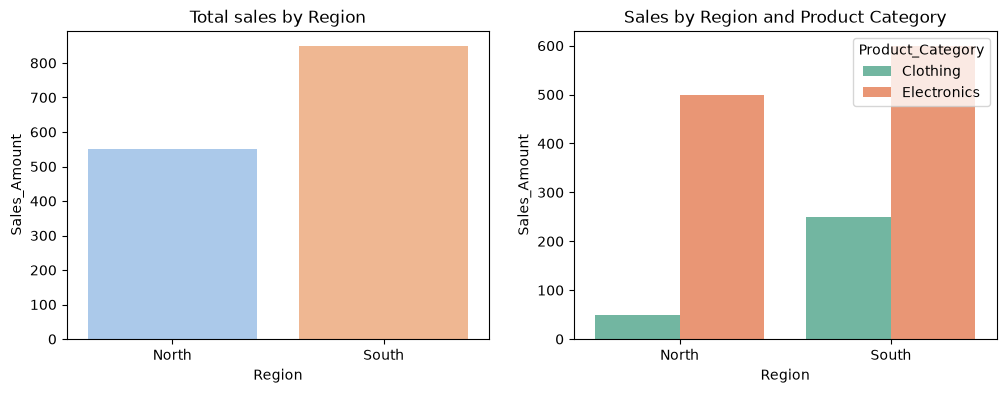

In [15]:
plt.figure(figsize = (12,4))

plt.subplot(1,2,1)
sns.barplot(x='Region', y = 'Sales_Amount', data = region_sales, palette = 'pastel', hue = 'Region', legend = False)
plt.title('Total sales by Region')

plt.subplot(1,2,2)
sns.barplot(x='Region', y = 'Sales_Amount', hue='Product_Category', data = region_product_sales, palette='Set2')
plt.title('Sales by Region and Product Category')

plt.show()